In [31]:
from pathlib import Path

folders = [
    "../models",
    "../dataset/registered_faces",
    "../src",
    "../screenshots"
]

for folder in folders:
    Path(folder).mkdir(parents=True, exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [32]:
!pip install --upgrade opencv-python numpy matplotlib streamlit

In [33]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

assert tuple(map(int, cv2.__version__.split(".")[:2])) >= (4, 10), \
    "Please upgrade OpenCV to 4.10 or later."

print("Environment ready!")

OpenCV: 5.0.0
NumPy: 2.5.4
Environment ready!


In [34]:
from pathlib import Path

yunet_path = Path("../models/face_detection_yunet_2023mar.onnx")
sface_path = Path("../models/face_recognition_sface_2021dec.onnx")

print("YuNet exists:", yunet_path.exists())
print("SFace exists:", sface_path.exists())

if not yunet_path.exists() or not sface_path.exists():
    print("Please download both models into the models folder.")
else:
    print("Both models are ready!")

YuNet exists: True
SFace exists: True
Both models are ready!


In [35]:
import cv2

detector = cv2.FaceDetectorYN.create(
    model=str(yunet_path),
    config="",
    input_size=(320, 320),
    score_threshold=0.8,
    nms_threshold=0.3,
    top_k=5000
)

print("YuNet loaded successfully!")

YuNet loaded successfully!


In [36]:
recognizer = cv2.FaceRecognizerSF.create(
    model=str(sface_path),
    config=""
)

print("SFace loaded successfully!")

SFace loaded successfully!


In [37]:
image_path = Path("../images/testFace.jpeg")

image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(
        "Image not found. Check ../images/test_face.jpg"
    )

height, width = image.shape[:2]

print("Image dimensions:", width, "x", height)

Image dimensions: 414 x 473


In [38]:
detector.setInputSize((width, height))

_, faces = detector.detect(image)

if faces is None:
    print("No face detected!")
else:
    print("Number of faces detected:", len(faces))
    print("Face detection output shape:", faces.shape)

Number of faces detected: 1
Face detection output shape: (1, 15)


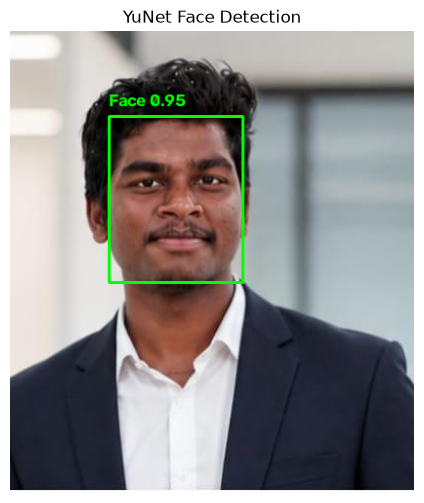

In [39]:
output = image.copy()

if faces is not None:
    for face in faces:
        x, y, w, h = face[:4].astype(int)

        cv2.rectangle(
            output,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        confidence = face[-1]

        cv2.putText(
            output,
            f"Face {confidence:.2f}",
            (x, max(20, y - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("YuNet Face Detection")
plt.show()

Aligned face shape: (112, 112, 3)


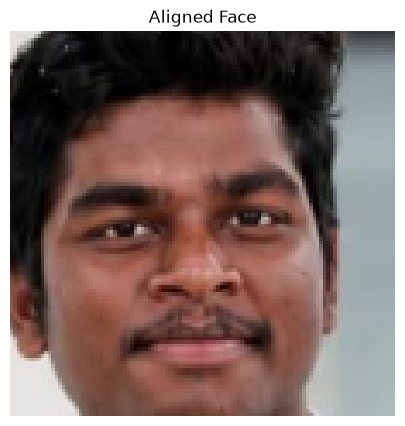

In [40]:
if faces is None or len(faces) == 0:
    raise ValueError("No face found to align.")

aligned_face = recognizer.alignCrop(image, faces[0])

print("Aligned face shape:", aligned_face.shape)

plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(aligned_face, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Aligned Face")
plt.show()

In [41]:
embedding = recognizer.feature(aligned_face)

print("Embedding shape:", embedding.shape)
print("Embedding data type:", embedding.dtype)
print("First 10 values:")
print(embedding[0][:10])

Embedding shape: (1, 128)
Embedding data type: float32
First 10 values:
[-2.1415927  -0.548682    1.4746641  -0.15519199 -0.32647854 -0.99801505
 -1.4819621   0.28394985 -2.1715233   0.5740555 ]


In [42]:
def get_face_embedding(image_path):

    img = cv2.imread(str(image_path))

    if img is None:
        print("Cannot read:", image_path)
        return None

    h, w = img.shape[:2]

    detector.setInputSize((w, h))

    _, detected_faces = detector.detect(img)

    if detected_faces is None or len(detected_faces) == 0:
        print("No face found:", image_path)
        return None

    # Select the face with the largest bounding-box area
    selected_face = max(
        detected_faces,
        key=lambda f: f[2] * f[3]
    )

    aligned = recognizer.alignCrop(img, selected_face)

    feature = recognizer.feature(aligned)

    return feature.flatten().astype(np.float32)

In [43]:
import json

dataset_path = Path("../dataset/registered_faces")

database = {}

for person_folder in dataset_path.iterdir():

    if not person_folder.is_dir():
        continue

    person_name = person_folder.name

    embeddings = []

    for image_file in person_folder.iterdir():

        if image_file.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        embedding = get_face_embedding(image_file)

        if embedding is not None:
            embeddings.append(embedding)

    if embeddings:
        # Average multiple embeddings, then normalize
        mean_embedding = np.mean(embeddings, axis=0)

        norm = np.linalg.norm(mean_embedding)

        if norm > 0:
            mean_embedding = mean_embedding / norm
            database[person_name] = mean_embedding.tolist()

print("Registered people:", list(database.keys()))

Registered people: ['AyushPandey', 'person2', 'Prawin', 'Priyanshu']


In [44]:
database_path = Path("../dataset/face_database.json")

with open(database_path, "w") as file:
    json.dump(database, file, indent=4)

print("Face database saved successfully!")

Face database saved successfully!


In [45]:
def cosine_similarity(embedding1, embedding2):

    embedding1 = np.asarray(embedding1, dtype=np.float32)
    embedding2 = np.asarray(embedding2, dtype=np.float32)

    norm1 = np.linalg.norm(embedding1)
    norm2 = np.linalg.norm(embedding2)

    if norm1 == 0 or norm2 == 0:
        return -1.0

    return float(
        np.dot(embedding1, embedding2) / (norm1 * norm2)
    )

In [46]:
def recognize_person(image_path, database, threshold=0.363):

    query_embedding = get_face_embedding(image_path)

    if query_embedding is None:
        return "No Face Detected", None

    best_name = "Unknown"
    best_score = -1.0

    for name, stored_embedding in database.items():

        score = cosine_similarity(
            query_embedding,
            stored_embedding
        )

        if score > best_score:
            best_score = score
            best_name = name

    if best_score < threshold:
        best_name = "Unknown"

    return best_name, best_score

In [47]:
test_image = "../images/testFace.jpeg"

name, score = recognize_person(
    test_image,
    database
)

print("Predicted identity:", name)
print("Similarity score:", score)

Predicted identity: Prawin
Similarity score: 0.9551384449005127


In [48]:
def recognize_multiple_faces(image, database, threshold=0.363):

    h, w = image.shape[:2]

    detector.setInputSize((w, h))

    _, faces = detector.detect(image)

    output = image.copy()
    results = []

    if faces is None:
        return output, results

    for face in faces:

        aligned = recognizer.alignCrop(image, face)

        feature = recognizer.feature(aligned).flatten()

        best_name = "Unknown"
        best_score = -1.0

        for name, stored_embedding in database.items():

            score = cosine_similarity(feature, stored_embedding)

            if score > best_score:
                best_score = score
                best_name = name

        if best_score < threshold:
            best_name = "Unknown"

        x, y, fw, fh = face[:4].astype(int)

        color = (0, 255, 0) if best_name != "Unknown" else (0, 0, 255)

        cv2.rectangle(
            output,
            (x, y),
            (x + fw, y + fh),
            color,
            2
        )

        label = f"{best_name}: {best_score:.2f}"

        cv2.putText(
            output,
            label,
            (x, max(20, y - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            color,
            2
        )

        results.append({
            "name": best_name,
            "similarity": best_score
        })

    return output, results

[{'name': 'Unknown', 'similarity': 0.2715590298175812}, {'name': 'Unknown', 'similarity': 0.2488749772310257}, {'name': 'Prawin', 'similarity': 0.7621924877166748}, {'name': 'Unknown', 'similarity': 0.2694973945617676}, {'name': 'Unknown', 'similarity': 0.23997290432453156}, {'name': 'Unknown', 'similarity': 0.2694036066532135}, {'name': 'Unknown', 'similarity': 0.11069472879171371}, {'name': 'Unknown', 'similarity': 0.24529415369033813}]


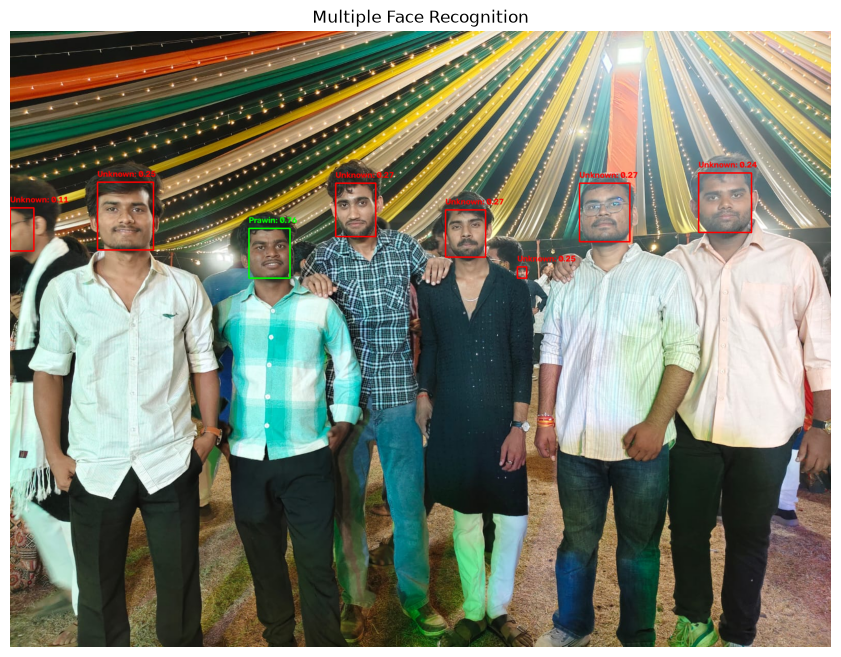

In [49]:
group_image = cv2.imread("../images/group_photo.jpg")

if group_image is None:
    raise FileNotFoundError("Add a group photo at ../images/group.jpg")

result_image, results = recognize_multiple_faces(
    group_image,
    database
)

print(results)

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Multiple Face Recognition")
plt.show()